# Notebook 11: Zeno and Anti-Zeno

**Goal:** Watch a decaying system with repeated division events, and find in Γ when watching slows the decay (Zeno)
and when it speeds it up (anti-Zeno).

By the end of this notebook you will be able to:
- Run a decay with a division event every τ, as Barandes's chain $\Gamma(\tau)^n$, and read off its effective rate
- Show that frequent events freeze the decay at the rate $\nu^2\tau$, set by notebook 07's agility alone
- Show that when the level sits away from where the band couples most strongly, watching can *nearly triple* the decay rate
- State the criterion in Γ: Zeno if survival at τ lies above the exponential it eventually follows, anti-Zeno if below,
  and see why notebook 10's single-event test is not the same thing
- Measure how strong the records must be: weak, frequent records act as dephasing at a rate $\gamma_\varphi$, and freeze the decay only
  once $\gamma_\varphi$ is comparable to the bandwidth

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from isp.decay import (DecayModel, lorentzian_couplings, band_energies,
                       asymptotic_decay, survival_with_records)

## 1. Watching a Decay

Notebook 10's flat band: one level $b$ coupled to $M$ band levels, golden-rule rate κ, bandwidth $W$. Now an environment records the
configuration every τ. Each record is a division event, so the process restarts from the recorded configuration, and
(Barandes, *Correspondence* §3.7, eqs. 57–58)

$$\Gamma(n\tau\leftarrow 0) = \Gamma(\tau)^n, \qquad \Gamma(\tau) = |U(\tau)|^2 .$$

A Markov chain, built from one indivisible step. The κ used throughout is read off Γ: the slope of $\ln P(t)$ at late times.

flat band: golden-rule κ = 0.1,  κ read off Γ = 0.1006,  intercept Z = 1.0129
bandwidth W = 10.0,  agility ν² = 0.1592

Full chain Γ(τ)ⁿ vs survival alone P(τ)ⁿ, at t = 1/κ (M = 250):
  τ = 0.05:  chain 0.9236   P(τ)ⁿ 0.9236   no events 0.3702
  τ =  0.5:  chain 0.5087   P(τ)ⁿ 0.5081   no events 0.3702
  τ =  2.0:  chain 0.3906   P(τ)ⁿ 0.3886   no events 0.3702


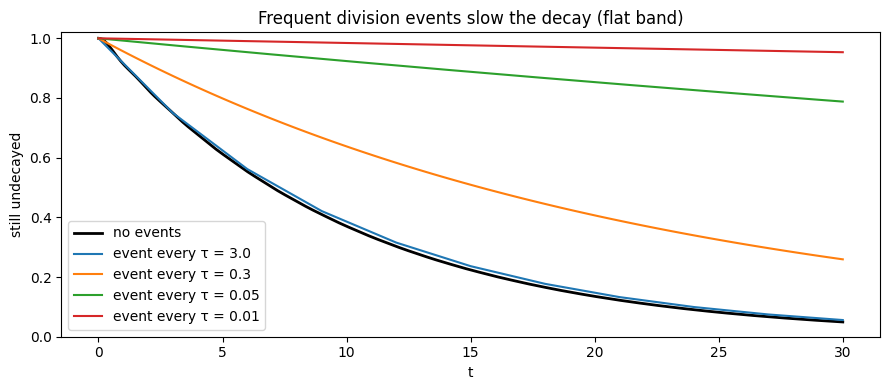

In [2]:
kappa_gr, W = 0.1, 10.0
flat = DecayModel(M=1000, delta=kappa_gr / 10, g=np.sqrt(kappa_gr * (kappa_gr / 10) / (2 * np.pi)))
kappa, Z = asymptotic_decay(flat, 20, 50)
print(f"flat band: golden-rule κ = {kappa_gr},  κ read off Γ = {kappa:.4f},  intercept Z = {Z:.4f}")
print(f"bandwidth W = {W},  agility ν² = {flat.nu2:.4f}")

small = DecayModel(M=250, delta=0.04, g=np.sqrt(kappa_gr * 0.04 / (2 * np.pi)))
print("\nFull chain Γ(τ)ⁿ vs survival alone P(τ)ⁿ, at t = 1/κ (M = 250):")
for tau in [0.05, 0.5, 2.0]:
    n = int(round(1 / kappa_gr / tau))
    chain = survival_with_records(small, tau, 1.0, n)[-1]
    print(f"  τ = {tau:4}:  chain {chain:.4f}   P(τ)ⁿ {small.survival([tau])[0] ** n:.4f}"
          f"   no events {small.survival([n * tau])[0]:.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
t_end = 30
tt = np.linspace(0, t_end, 400)
ax.plot(tt, flat.survival(tt), 'k', lw=2, label='no events')
for tau in [3.0, 0.3, 0.05, 0.01]:
    n = np.arange(0, int(t_end / tau) + 1)
    ax.plot(n * tau, flat.survival([tau])[0] ** n, label=f'event every τ = {tau}')
ax.set_xlabel('t'); ax.set_ylabel('still undecayed'); ax.set_ylim(0, 1.02); ax.legend()
ax.set_title('Frequent division events slow the decay (flat band)')
plt.tight_layout(); plt.show()

## 2. Zeno: Frequent Events Freeze the Decay

With an event every τ, and neglecting re-excitation from the band (under 1% here, section 1), survival after $n$ events is $P(\tau)^n = e^{-\gamma_{\rm eff}\, n\tau}$, so the effective rate is

$$\gamma_{\rm eff}(\tau) = -\frac{\ln P(\tau)}{\tau}.$$

At short times $P(\tau) \approx 1 - \nu^2\tau^2$ (notebook 10), so $\gamma_{\rm eff} \approx \nu^2\tau \to 0$. At long τ, $P(\tau) \approx Z e^{-\kappa\tau}$, so $\gamma_{\rm eff} \approx \kappa - \ln Z/\tau$.

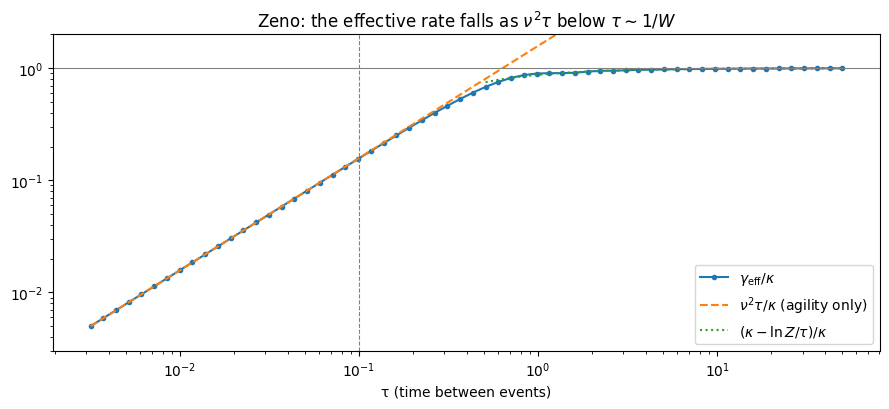

τ =  0.003:  γ_eff/κ = 0.0047   ν²τ/κ = 0.0047   (κ − ln Z/τ)/κ = -41.3933
τ =   0.01:  γ_eff/κ = 0.0158   ν²τ/κ = 0.0158   (κ − ln Z/τ)/κ = -11.7180
τ =   0.03:  γ_eff/κ = 0.0474   ν²τ/κ = 0.0474   (κ − ln Z/τ)/κ = -3.2393
τ =    0.1:  γ_eff/κ = 0.1571   ν²τ/κ = 0.1581   (κ − ln Z/τ)/κ = -0.2718
τ =      1:  γ_eff/κ = 0.8973   ν²τ/κ = 1.5814   (κ − ln Z/τ)/κ = +0.8728
τ =     10:  γ_eff/κ = 0.9874   ν²τ/κ = 15.8140   (κ − ln Z/τ)/κ = +0.9873


In [3]:
taus = np.logspace(-2.5, 1.7, 60)
geff = -np.log(flat.survival(taus)) / taus

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.loglog(taus, geff / kappa, 'o-', ms=3, label='$\\gamma_{\\rm eff}/\\kappa$')
ax.loglog(taus, flat.nu2 * taus / kappa, '--', label='$\\nu^2\\tau/\\kappa$ (agility only)')
long = taus > 0.5
ax.loglog(taus[long], (kappa - np.log(Z) / taus[long]) / kappa, ':', label='$(\\kappa - \\ln Z/\\tau)/\\kappa$')
ax.axhline(1, color='gray', lw=0.8); ax.axvline(1 / W, color='gray', lw=0.8, ls='--')
ax.set_xlabel('τ (time between events)'); ax.set_ylim(3e-3, 2); ax.legend()
ax.set_title('Zeno: the effective rate falls as $\\nu^2\\tau$ below $\\tau \\sim 1/W$')
plt.tight_layout(); plt.show()

for tau in [0.003, 0.01, 0.03, 0.1, 1, 10]:
    g = -np.log(flat.survival([tau])[0]) / tau
    print(f"τ = {tau:6}:  γ_eff/κ = {g / kappa:.4f}   ν²τ/κ = {flat.nu2 * tau / kappa:.4f}"
          f"   (κ − ln Z/τ)/κ = {(kappa - np.log(Z) / tau) / kappa:+.4f}")

## 3. Anti-Zeno: Watching Can Speed It Up

Now make the band **structured**: the coupling $g_k^2$ is a Lorentzian peaked at energy 2 (half-width 0.5), while the level $b$ sits at energy 0, out in the tail.
The golden rule only sees the weak coupling at $b$'s own energy. But over an interval τ between records, transitions need conserve energy only to within about $2\pi/\tau$,
and once that window reaches the peak, decay speeds up.

structured band: golden-rule κ = 0.0234,  κ read off Γ = 0.0221,  intercept Z = 0.9608


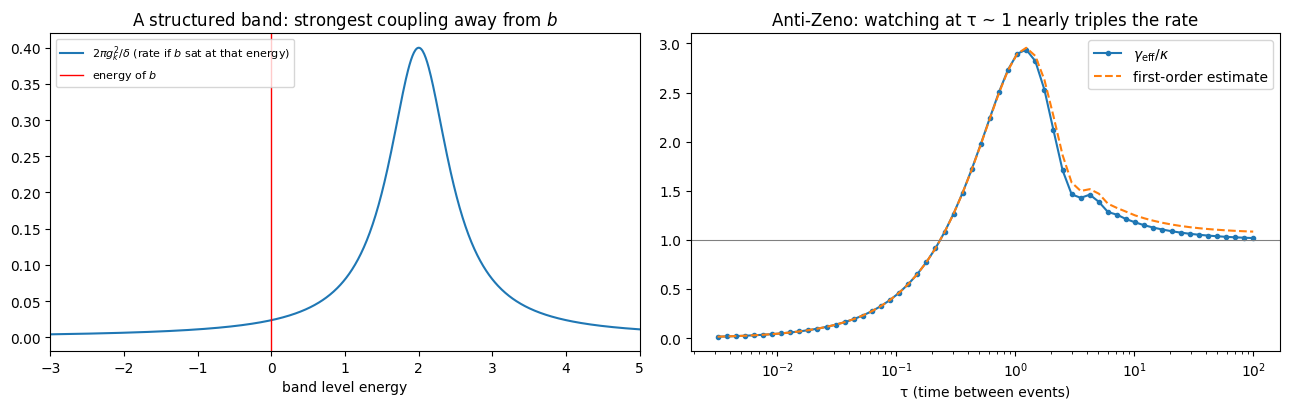

τ =   0.01:  γ_eff/κ = 0.044
τ =    0.1:  γ_eff/κ = 0.435
τ =    0.3:  γ_eff/κ = 1.252
τ =      1:  γ_eff/κ = 2.867
τ =      3:  γ_eff/κ = 1.459
τ =     10:  γ_eff/κ = 1.181
τ =     30:  γ_eff/κ = 1.060
τ =    100:  γ_eff/κ = 1.018


In [4]:
Wb, db, peak, width = 20.0, 0.01, 2.0, 0.5
Mb = int(Wb / db)
g0 = np.sqrt(0.4 * db / (2 * np.pi))
gk = lorentzian_couplings(Mb, db, g0, peak, width)
st = DecayModel(M=Mb, delta=db, g=g0, couplings=gk)
kappa_s, Z_s = asymptotic_decay(st, 50, 250)
print(f"structured band: golden-rule κ = {st.rate:.4f},  κ read off Γ = {kappa_s:.4f},  intercept Z = {Z_s:.4f}")

taus_b = np.logspace(-2.5, 2, 60)
geff_b = -np.log(st.survival(taus_b)) / taus_b
eps = band_energies(Mb, db)
first = np.array([(4 * gk ** 2 * np.sin(eps * t / 2) ** 2 / eps ** 2).sum() / t for t in taus_b])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(eps, 2 * np.pi * gk ** 2 / db, label='$2\\pi g_k^2/\\delta$ (rate if $b$ sat at that energy)')
ax[0].axvline(0, color='red', lw=1, label='energy of $b$')
ax[0].set_xlim(-3, 5); ax[0].set_xlabel('band level energy'); ax[0].legend(fontsize=8)
ax[0].set_title('A structured band: strongest coupling away from $b$')
ax[1].semilogx(taus_b, geff_b / kappa_s, 'o-', ms=3, label='$\\gamma_{\\rm eff}/\\kappa$')
ax[1].semilogx(taus_b, first / kappa_s, '--', label='first-order estimate')
ax[1].axhline(1, color='gray', lw=0.8)
ax[1].set_xlabel('τ (time between events)'); ax[1].legend()
ax[1].set_title('Anti-Zeno: watching at τ ~ 1 nearly triples the rate')
plt.tight_layout(); plt.show()

for tau in [0.01, 0.1, 0.3, 1, 3, 10, 30, 100]:
    g = -np.log(st.survival([tau])[0]) / tau
    print(f"τ = {tau:6}:  γ_eff/κ = {g / kappa_s:.3f}")

## 4. The Criterion, in Γ

Neglecting re-excitation from the band, survival after $n$ events is $P(\tau)^n$; without events it eventually follows $Z e^{-\kappa n\tau}$. So the long-run verdict depends on one comparison:

$$\textbf{Zeno at interval }\tau \iff P(\tau) > e^{-\kappa\tau}, \qquad \textbf{anti-Zeno} \iff P(\tau) < e^{-\kappa\tau}.$$

Watching helps exactly when survival at τ is **ahead** of the exponential it eventually follows. Both sides are read off Γ. At long τ the comparison reduces to the intercept:
$\gamma_{\rm eff} \approx \kappa - \ln Z/\tau$, so $Z > 1$ means Zeno and $Z < 1$ means anti-Zeno. This is the criterion of Facchi, Nakazato and Pascazio, Phys. Rev. Lett. 86, 2699 (2001),
eqs. 2–4, restated in Facchi and Pascazio (2001), §3, together with the role of $Z$ (their Figs. 3–4):
the crossover interval is where $P(t)$ meets $e^{-\kappa t}$. What Γ adds is that both sides are entries of one transition matrix.

Notebook 10 asked a different question: does **one** event at τ raise survival at $2\tau$, i.e. is $P(\tau)^2 > P(2\tau)$? The table compares the two.
The last lines check two things: which κ to use, and whether the flat band's $P(2\tau)$ at τ = 100 is still on its exponential.

In [5]:
print(f"flat band: Z = {Z:.4f}    structured band: Z = {Z_s:.4f}\n")
for name, m, k in [("flat", flat, kappa), ("structured", st, kappa_s)]:
    for tau in [0.01, 0.1, 0.3, 1, 3, 10, 30, 100]:
        p1, p2 = m.survival([tau, 2 * tau])
        regime = "Zeno" if p1 > np.exp(-k * tau) else "anti-Zeno"
        one = "raises" if p1 ** 2 > p2 else "lowers"
        flag = "" if (regime == "Zeno") == (one == "raises") else f"   <- the two disagree (P(2τ) − P(τ)² = {p2 - p1 ** 2:+.1e})"
        print(f"{name:10s} τ = {tau:6}:  long run {regime:9s}  one event {one} survival{flag}")

print("\nflat band, P(τ) / e^(−κτ) with κ read off Γ and with the golden-rule κ:")
for tau in [10, 30, 100]:
    p1 = flat.survival([tau])[0]
    print(f"  τ = {tau:3}:  {p1 / np.exp(-kappa * tau):.4f} (κ = {kappa:.4f})   {p1 / np.exp(-kappa_gr * tau):.4f} (κ = {kappa_gr})")
p200 = flat.survival([200.0])[0]
print(f"flat band at t = 200: P = {p200:.2e},  Z e^(−κt) = {Z * np.exp(-kappa * 200):.2e}")

flat band: Z = 1.0129    structured band: Z = 0.9608

flat       τ =   0.01:  long run Zeno       one event raises survival
flat       τ =    0.1:  long run Zeno       one event raises survival
flat       τ =    0.3:  long run Zeno       one event raises survival
flat       τ =      1:  long run Zeno       one event raises survival
flat       τ =      3:  long run Zeno       one event raises survival
flat       τ =     10:  long run Zeno       one event raises survival
flat       τ =     30:  long run Zeno       one event raises survival
flat       τ =    100:  long run Zeno       one event lowers survival   <- the two disagree (P(2τ) − P(τ)² = +6.0e-10)
structured τ =   0.01:  long run Zeno       one event raises survival
structured τ =    0.1:  long run Zeno       one event raises survival
structured τ =    0.3:  long run anti-Zeno  one event raises survival   <- the two disagree (P(2τ) − P(τ)² = -1.2e-02)
structured τ =      1:  long run anti-Zeno  one event lowers survival
structur

## 5. How Strong Must the Records Be?

So far every record was perfect. A weaker record only partly divides the process: each one multiplies the off-diagonal elements of the
density matrix (in the configuration basis) by $1 - \varepsilon$. That is notebook 06's imperfect record and notebook 08's phase damping.
$\varepsilon = 1$ is a full division event; $\varepsilon = 0$ is no record. Frequent weak records act like steady dephasing at the rate

$$\gamma_\varphi = -\frac{\ln(1-\varepsilon)}{\tau}.$$

The prediction to test comes from Kofman and Kurizki's (2001) dephasing result. Each band level is fed at the rate $2g^2\gamma_\varphi/(\varepsilon_k^2+\gamma_\varphi^2)$, and summing over the flat band gives $\gamma_{\rm eff} = \kappa\cdot\frac{2}{\pi}\arctan\!\big(W/2\gamma_\varphi\big)$: no Zeno while $\gamma_\varphi \ll W$, and freezing as $2\nu^2/\gamma_\varphi$ once $\gamma_\varphi \gg W$.

no records: rate 0.1006  (M = 250 band, golden rule 0.1000)



τ = 0.05, ε = 0.02:  γφ =   0.40   γ_eff/κ measured 0.920   predicted 0.949


τ = 0.05, ε = 0.05:  γφ =   1.03   γ_eff/κ measured 0.857   predicted 0.871


τ = 0.02, ε = 0.04:  γφ =   2.04   γ_eff/κ measured 0.746   predicted 0.753


τ = 0.05, ε =  0.1:  γφ =   2.11   γ_eff/κ measured 0.739   predicted 0.746
τ =  0.1, ε =  0.2:  γφ =   2.23   γ_eff/κ measured 0.728   predicted 0.733


τ =  0.2, ε =  0.4:  γφ =   2.55   γ_eff/κ measured 0.708   predicted 0.699


τ = 0.05, ε =  0.3:  γφ =   7.13   γ_eff/κ measured 0.390   predicted 0.389


τ = 0.05, ε =  0.5:  γφ =  13.86   γ_eff/κ measured 0.227   predicted 0.220



perfect records (ε = 1) every τ = 0.05: measured 0.079, which follows ν²τ/κ = 0.079 instead of the formula


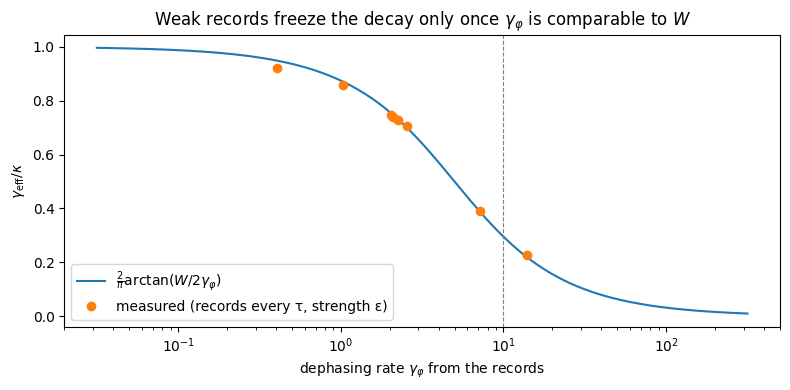

In [6]:
def rate_with_records(tau, eps, t1=5.0, t2=20.0):
    s = survival_with_records(small, tau, eps, int(round(t2 / tau)))
    return -np.log(s[-1] / s[int(round(t1 / tau))]) / (t2 - t1)

k_small = rate_with_records(0.5, 0.0)
print(f"no records: rate {k_small:.4f}  (M = 250 band, golden rule {small.rate:.4f})\n")
rows = []
for tau, e in [(0.05, 0.02), (0.05, 0.05), (0.02, 0.04), (0.05, 0.1), (0.1, 0.2), (0.2, 0.4), (0.05, 0.3), (0.05, 0.5)]:
    g_phi = -np.log(1 - e) / tau
    pred = 2 / np.pi * np.arctan(W / (2 * g_phi))
    meas = rate_with_records(tau, e) / k_small
    rows.append((g_phi, meas, pred))
    print(f"τ = {tau:4}, ε = {e:4}:  γφ = {g_phi:6.2f}   γ_eff/κ measured {meas:.3f}   predicted {pred:.3f}")
print(f"\nperfect records (ε = 1) every τ = 0.05: measured {rate_with_records(0.05, 1.0) / k_small:.3f}, "
      f"which follows ν²τ/κ = {small.nu2 * 0.05 / k_small:.3f} instead of the formula")

rows = np.array(rows)
gg = np.logspace(-1.5, 2.5, 200)
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(gg, 2 / np.pi * np.arctan(W / (2 * gg)), label='$\\frac{2}{\\pi}\\arctan(W/2\\gamma_\\varphi)$')
ax.semilogx(rows[:, 0], rows[:, 1], 'o', label='measured (records every τ, strength ε)')
ax.axvline(W, color='gray', lw=0.8, ls='--')
ax.set_xlabel('dephasing rate $\\gamma_\\varphi$ from the records'); ax.set_ylabel('$\\gamma_{\\rm eff}/\\kappa$'); ax.legend()
ax.set_title('Weak records freeze the decay only once $\\gamma_\\varphi$ is comparable to $W$')
plt.tight_layout(); plt.show()

## Summary

- **Watching is a chain of division events**: $\Gamma(n\tau) = \Gamma(\tau)^n$ (Barandes eq. 57). For decay it acts on survival alone,
  $P(\tau)^n$, to better than 1% here.
- **Zeno.** In a flat band, $\gamma_{\rm eff} = \nu^2\tau$ for $\tau \lesssim 1/W$: frequent events freeze the decay at a rate set by notebook 07's agility
  (a frequency, in this lab's units). For longer τ the rate approaches κ from below, as $\kappa - \ln Z/\tau$ with $Z > 1$.
- **Anti-Zeno.** When the level sits in the tail of a structured band, watching at τ ≈ 1 makes it decay nearly three times faster.
  Its intercept is $Z < 1$, so watching speeds it up at long τ. Numerically it does so for every τ above about 0.23 and slows it only below that.
- **The criterion is stated in Γ**: Zeno iff $P(\tau) > e^{-\kappa\tau}$, with κ read off Γ, i.e. iff survival at τ is ahead of its eventual exponential.
  Notebook 10's single-event test is a different question; the two genuinely disagree for the structured band at τ = 0.3. The flat band's
  mismatch at τ = 100 is not physics: $P(2\tau)$ is then $2.45\times10^{-9}$, in the late-time tail of this finite band (33% above $Ze^{-\kappa t}$), and the
  one-event sign is set by a difference of $6\times10^{-10}$. κ must be read off Γ: the golden-rule κ = 0.1 would label the flat band anti-Zeno at τ = 30 and 100. (Both the 0.6% and $Z>1$ are the band-edge self-energy, $Z\approx(1-4g^2/\delta W)^{-2}$.)
- **Imperfect records.** Weak, frequent records act as dephasing at $\gamma_\varphi = -\ln(1-\varepsilon)/\tau$ and give
  $\gamma_{\rm eff} \approx \kappa\cdot\frac{2}{\pi}\arctan(W/2\gamma_\varphi)$ when $\gamma_\varphi \gg \kappa$. Freezing needs $\gamma_\varphi$ comparable to $W$.

Caveats: one flat and one Lorentzian band; the arctan formula borrows a rate-equation step and fails when $\gamma_\varphi$ is comparable to κ;
κ for the structured band is 6% below its golden-rule estimate (about two-thirds of it from the level shift), which is why κ is read off Γ.

Prior work: the criterion is Facchi, Nakazato and Pascazio, Phys. Rev. Lett. 86, 2699 (2001), eqs. 2–4, restated almost verbatim in Facchi and
Pascazio (2001), §3, including the long-τ role of $Z$; the freezing rate $\nu^2\tau$ is the textbook Zeno result (Misra & Sudarshan 1977), in exactly
this form Facchi and Pascazio's eq. 3.3 ($\gamma_{\rm eff} \sim \tau/\tau_Z^2$); anti-Zeno in a structured band is Kofman & Kurizki (2000); and the arctan formula is
Kofman and Kurizki's (2001) dephasing result plus one integral over a flat band, whose strong-record limit matches Facchi and Pascazio's eqs. 4.9–4.10
and Schulman (1998). The only addition here is the reading in Barandes's terms, watching as a chain of division events (his *Correspondence*
§3.7, eq. 57); an ISP treatment of the Zeno effects was not found in our searches.